In [1]:
import pandas as pd

df = pd.read_csv("PJME_hourly.csv", parse_dates=["Datetime"], index_col="Datetime")
df = df.sort_index()
print(df.head())
print(df.info())

                     PJME_MW
Datetime                    
2002-01-01 01:00:00  30393.0
2002-01-01 02:00:00  29265.0
2002-01-01 03:00:00  28357.0
2002-01-01 04:00:00  27899.0
2002-01-01 05:00:00  28057.0
<class 'pandas.DataFrame'>
DatetimeIndex: 145366 entries, 2002-01-01 01:00:00 to 2018-08-03 00:00:00
Data columns (total 1 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   PJME_MW  145366 non-null  float64
dtypes: float64(1)
memory usage: 2.2 MB
None


In [2]:
print("Tekrar eden zaman damgası:", df.index.duplicated().sum())

tam_aralik = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Eksik saat sayısı:", len(tam_aralik.difference(df.index)))

print(df.describe())

Tekrar eden zaman damgası: 4
Eksik saat sayısı: 30
             PJME_MW
count  145366.000000
mean    32080.222831
std      6464.012166
min     14544.000000
25%     27573.000000
50%     31421.000000
75%     35650.000000
max     62009.000000


In [3]:
# Tekrar edenlerin ilkini tut
df = df[~df.index.duplicated(keep="first")]

# Eksik saatleri ekle, değerlerini komşu saatlerden doldur
df = df.asfreq("h")
df["PJME_MW"] = df["PJME_MW"].interpolate()

print(df.isna().sum())
print(len(df))

PJME_MW    0
dtype: int64
145392


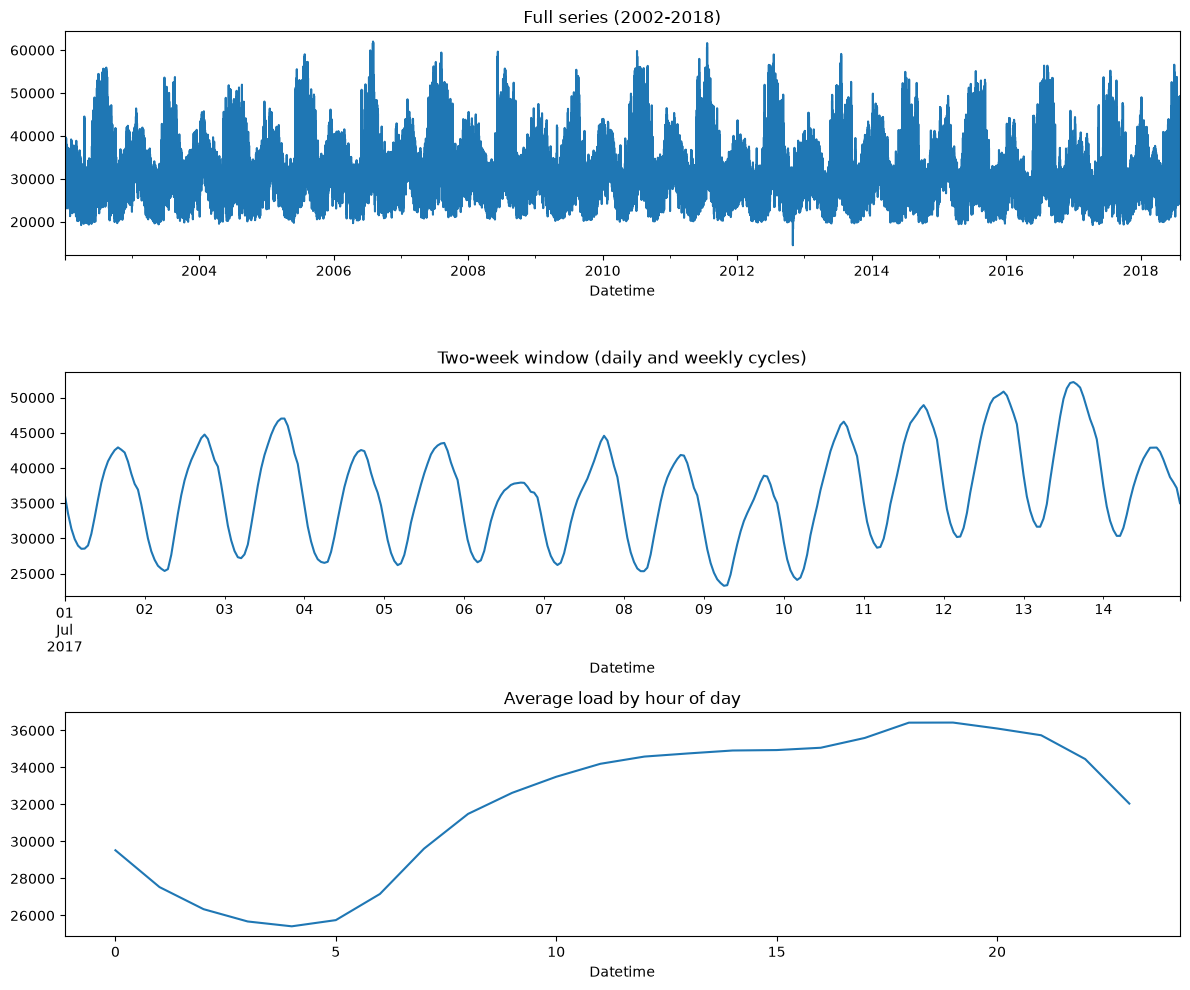

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

df["PJME_MW"].plot(ax=axes[0], title="Full series (2002-2018)")
df.loc["2017-07-01":"2017-07-14", "PJME_MW"].plot(ax=axes[1], title="Two-week window (daily and weekly cycles)")
df.groupby(df.index.hour)["PJME_MW"].mean().plot(ax=axes[2], title="Average load by hour of day")

plt.tight_layout()
plt.show()

In [5]:
data = pd.DataFrame({"y": df["PJME_MW"]})

# Takvim özellikleri
data["hour"] = data.index.hour
data["dayofweek"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

# Gecikmeli (lag) özellikler
data["lag_1"] = data["y"].shift(1)      # 1 saat önce
data["lag_24"] = data["y"].shift(24)    # dün aynı saat
data["lag_168"] = data["y"].shift(168)  # geçen hafta aynı saat

# Hareketli ortalama (shift(1): tahmin edilen saatin kendi değerini kullanmamak için)
data["roll_24"] = data["y"].shift(1).rolling(24).mean()

data = data.dropna()
print(data.shape)
data.head()

(145224, 9)


,y,hour,dayofweek,month,is_weekend,lag_1,lag_24,lag_168,roll_24
Datetime,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,0,31187.0,26862.0,30393.0,33452.583333
2002-01-08 02:00:00,28670.0,2,1,1,0,29445.0,25976.0,29265.0,33560.208333
2002-01-08 03:00:00,28375.0,3,1,1,0,28670.0,25641.0,28357.0,33672.458333
2002-01-08 04:00:00,28542.0,4,1,1,0,28375.0,25666.0,27899.0,33786.375000
2002-01-08 05:00:00,29261.0,5,1,1,0,28542.0,26328.0,28057.0,33906.208333


In [6]:
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]

features = [c for c in data.columns if c != "y"]
X_train, y_train = train[features], train["y"]
X_test, y_test = test[features], test["y"]

print("Eğitim:", train.index.min(), "→", train.index.max())
print("Test:  ", test.index.min(), "→", test.index.max())

Eğitim: 2002-01-08 01:00:00 → 2015-04-10 19:00:00
Test:   2015-04-10 20:00:00 → 2018-08-03 00:00:00


In [7]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def metrikler(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": round(mae, 1), "RMSE": round(rmse, 1), "MAPE %": round(mape, 2)}

sonuclar = {}

# Naive baseline'lar
sonuclar["Naive (dün aynı saat)"] = metrikler(y_test, X_test["lag_24"])
sonuclar["Naive (geçen hafta aynı saat)"] = metrikler(y_test, X_test["lag_168"])

# Linear Regression
lr = LinearRegression().fit(X_train, y_train)
sonuclar["Linear Regression"] = metrikler(y_test, lr.predict(X_test))

# Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
sonuclar["Random Forest"] = metrikler(y_test, rf.predict(X_test))

pd.DataFrame(sonuclar).T

,MAE,RMSE,MAPE %
Naive (dün aynı saat),2184.3,3009.0,6.93
Naive (geçen hafta aynı saat),3391.9,4670.3,10.56
Linear Regression,977.0,1254.2,3.15
Random Forest,336.3,462.7,1.07


In [8]:
sonuclar["Naive (1 saat önce)"] = metrikler(y_test, X_test["lag_1"])
pd.DataFrame(sonuclar).T

,MAE,RMSE,MAPE %
Naive (dün aynı saat),2184.3,3009.0,6.93
Naive (geçen hafta aynı saat),3391.9,4670.3,10.56
Linear Regression,977.0,1254.2,3.15
Random Forest,336.3,462.7,1.07
Naive (1 saat önce),1070.0,1373.8,3.48


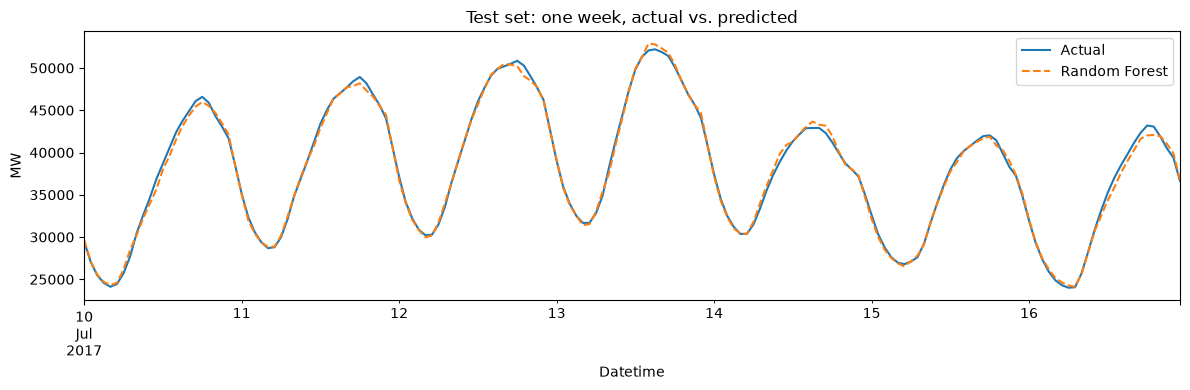

In [9]:
import matplotlib.pyplot as plt

rf_pred = pd.Series(rf.predict(X_test), index=y_test.index)
hafta = slice("2017-07-10", "2017-07-16")

plt.figure(figsize=(12, 4))
y_test.loc[hafta].plot(label="Actual")
rf_pred.loc[hafta].plot(label="Random Forest", linestyle="--")
plt.ylabel("MW")
plt.title("Test set: one week, actual vs. predicted")
plt.legend()
plt.tight_layout()
plt.show()

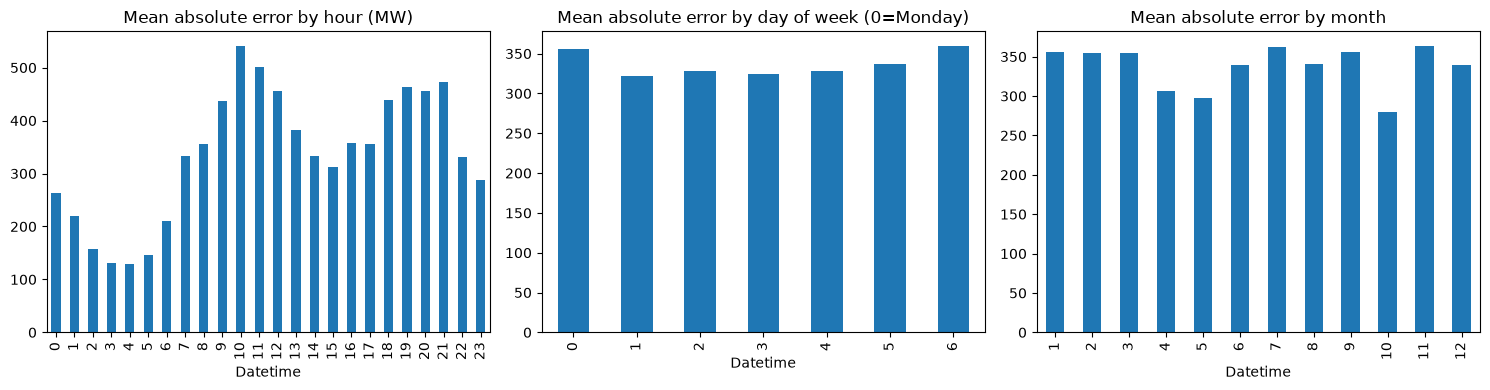

Top 10 largest errors:
Datetime
2015-06-23 19:00:00    3300.0
2018-07-17 16:00:00    3082.0
2016-07-18 17:00:00    2848.0
2017-02-18 21:00:00    2718.0
2015-08-30 12:00:00    2662.0
2015-12-24 20:00:00    2642.0
2018-01-06 18:00:00    2569.0
2015-11-26 07:00:00    2540.0
2015-09-07 12:00:00    2538.0
2017-02-18 11:00:00    2522.0
dtype: float64


In [10]:
hata = (y_test - rf_pred).abs()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
hata.groupby(hata.index.hour).mean().plot(kind="bar", ax=axes[0], title="Mean absolute error by hour (MW)")
hata.groupby(hata.index.dayofweek).mean().plot(kind="bar", ax=axes[1], title="Mean absolute error by day of week (0=Monday)")
hata.groupby(hata.index.month).mean().plot(kind="bar", ax=axes[2], title="Mean absolute error by month")
plt.tight_layout()
plt.show()

print("Top 10 largest errors:")
print(hata.sort_values(ascending=False).head(10).round(0))

In [18]:
def kalman_1step(y, q_level, q_slope, r):
    F = np.array([[1., 1.], [0., 1.]])
    FT = F.T
    Q = np.diag([q_level, q_slope])
    I = np.eye(2)
    x = np.array([y[0], 0.])
    P = I * 1e4
    n = len(y)
    preds, S_all = np.zeros(n), np.zeros(n)
    for t in range(n):
        x_pred = F @ x
        P_pred = F @ P @ FT + Q
        preds[t] = x_pred[0]
        S = P_pred[0, 0] + r
        S_all[t] = S
        K = P_pred[:, 0] / S
        x = x_pred + K * (y[t] - x_pred[0])
        P = P_pred - np.outer(K, P_pred[0, :])
    return preds, S_all

In [19]:
y_all = data["y"].values
y_tune = y_all[:20000]

for ql in [5e5, 1e6, 2e6, 4e6]:
    p, S = kalman_1step(y_tune, ql, 0.01, 0.1)
    e = y_tune[100:] - p[100:]
    nll = np.mean(0.5 * (np.log(2*np.pi*S[100:]) + e**2 / S[100:]))
    print(f"q_level={ql:.0e}  NLL={nll:.3f}  MAE={np.mean(np.abs(e)):.1f}")

q_level=5e+05  NLL=9.620  MAE=1102.5
q_level=1e+06  NLL=8.897  MAE=1102.5
q_level=2e+06  NLL=8.708  MAE=1102.5
q_level=4e+06  NLL=8.787  MAE=1102.4


,MAE,RMSE,MAPE %
Naive (dün aynı saat),2184.3,3009.0,6.93
Naive (geçen hafta aynı saat),3391.9,4670.3,10.56
Linear Regression,977.0,1254.2,3.15
Random Forest,336.3,462.7,1.07
Naive (1 saat önce),1070.0,1373.8,3.48
Kalman (local linear trend),1070.0,1373.9,3.48


95% interval coverage: 94.9 %
Mean interval width (MW): 5544.0


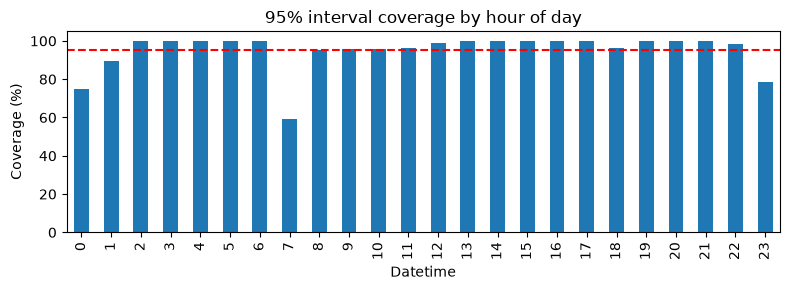

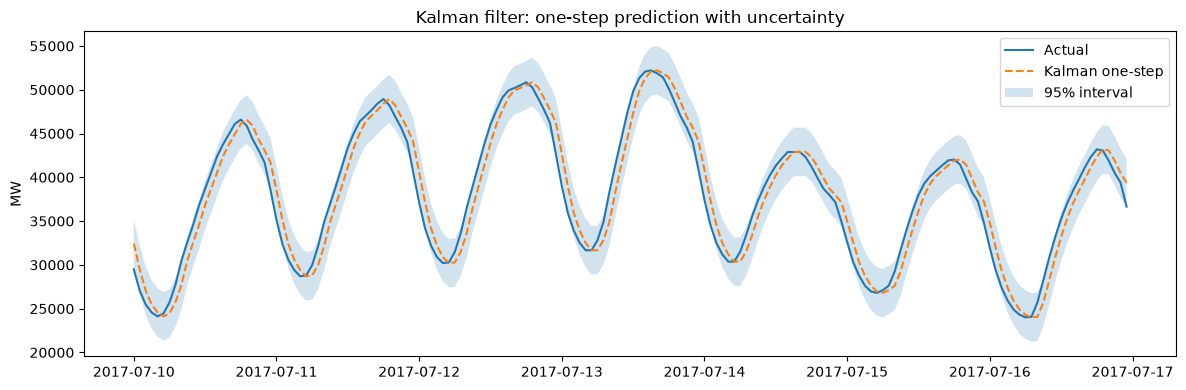

In [20]:
ql, qs, r = 2e6, 0.01, 0.1   # Hücre 2'de NLL'si en düşük çıkan q_level'i buraya yaz
preds, S_all = kalman_1step(y_all, ql, qs, r)

split = int(len(data) * 0.8)
k_pred = preds[split:]
k_std = np.sqrt(S_all[split:])
k_true = y_all[split:]

sonuclar["Kalman (local linear trend)"] = metrikler(pd.Series(k_true), pd.Series(k_pred))
display(pd.DataFrame(sonuclar).T)

lo, hi = k_pred - 1.96 * k_std, k_pred + 1.96 * k_std
inside = (k_true >= lo) & (k_true <= hi)
print("95% interval coverage:", round(inside.mean() * 100, 1), "%")
print("Mean interval width (MW):", round(np.mean(hi - lo), 0))

idx_test = data.index[split:]
cov_by_hour = pd.Series(inside, index=idx_test).groupby(idx_test.hour).mean() * 100
plt.figure(figsize=(8, 3))
cov_by_hour.plot(kind="bar")
plt.axhline(95, color="red", linestyle="--")
plt.ylabel("Coverage (%)"); plt.title("95% interval coverage by hour of day")
plt.tight_layout(); plt.show()

w = (idx_test >= "2017-07-10") & (idx_test < "2017-07-17")
plt.figure(figsize=(12, 4))
plt.plot(idx_test[w], k_true[w], label="Actual")
plt.plot(idx_test[w], k_pred[w], "--", label="Kalman one-step")
plt.fill_between(idx_test[w], lo[w], hi[w], alpha=0.2, label="95% interval")
plt.ylabel("MW"); plt.title("Kalman filter: one-step prediction with uncertainty")
plt.legend(); plt.tight_layout(); plt.show()